# Zoolog

Zoolog, penguen türlerini tanıma konusunda uzmandır. Uzmanımızın adlandırabildiği 3 penguen türü şunlardır:

<img src="https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/01-Fundamentals-of-Machine-Learning/palmer-penguins.png" width=1000>

Peki siz onları ayırt edebiliyor musunuz?


## Görev

Penguenler hakkında hiçbir şey bilmediğimiz için, bu penguenleri özelliklerine göre sınıflandırmak için bir Makine Öğrenimi algoritması kullanalım.

## Dataset’i yükleyin

Seaborn [Penguins dataset](https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv)’ini bir DataFrame içine yükleyelim. İşleri kolaylaştırmak için `nans` değerlerinden kurtulun! Aşağıdaki çıktıyı elde etmelisiniz:

<img src='https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/01-Fundamentals-of-Machine-Learning/penguin-df.png' width=600>

In [1]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.model_selection import cross_validate

penguin_df = sns.load_dataset("penguins").dropna()
penguin_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


❓Penguenlerin özellikleri nelerdir?

<img src='https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/gentoo.png' width=700>

❓Bu veri setinde kaç tür penguen var?

In [2]:
penguin_df["species"].nunique()

3

❓Veri setinde her tür için kaç gözlem var?

In [3]:
penguin_df["species"].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [4]:
penguin_df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


##  Veri görselleştirme (Data visualization)

‘bill_length_mm’ değerini ‘bill_depth_mm’ değerine göre, her tür için farklı bir renk kullanarak grafikte gösterin:

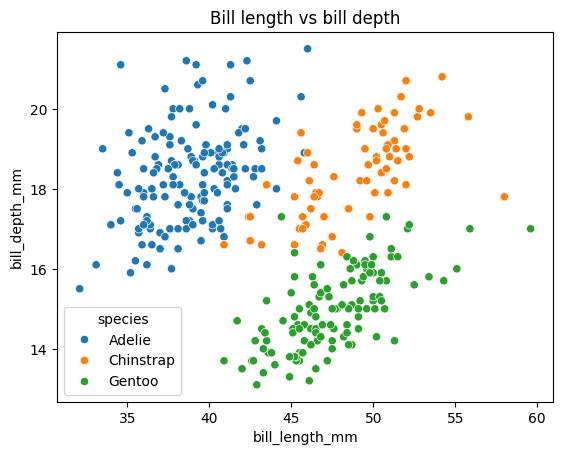

In [5]:
sns.scatterplot(data=penguin_df, x="bill_length_mm", y="bill_depth_mm", hue="species")
plt.title("Bill length vs bill depth");

❓Gözlemlerinize dayanarak bu türleri ayırt edebiliyor musunuz?

**gentoo** türü, diğer 2 türe göre açıkça daha uzun yüzgeçlere sahip gibi görünüyor.

## Modelleme

Çoklu sınıf sorununu çözmek için iki strateji vardır:

- Bire bir (One vs One)
- Bire tüm (Bire geri kalan)(One vs All)


### One vs One
- Dataset içindeki **her bir sınıf çifti için bir model** eğitilir
- Tahmin aşamasında, **en fazla oyu alan sınıf** seçilir

<img src='images/ovo_multiclass.png' width=500 style='margin:auto'> 


👍 Sınıf çiftlerine özgü farkları dikkate alır


👎 Çok sayıda alt model oluşturur: hesaplama açısından maliyetlidir


### One vs Rest (One vs All)

- **Her bir sınıf için**, diğer tüm sınıflara karşı **tek bir model** eğitilir
- Tahmin aşamasında, **en yüksek olasılığa sahip sınıf** seçilir

<img src='images/ova_multiclass.png' width=500 style='margin:auto'> 

👍 Hesaplama açısından daha az maliyetlidir


👎 Sınıfların bir araya getirilmesiyle, sınıf çiftlerine özgü farklar kaybolur ve etkileri azalır

## One vs Rest

👇 Penguen türünü **sayısal (numerical)** feature’lara göre tahmin eden bir modeli değerlendirin. scikit-learn içinde, temel model olarak LogisticRegression kullanan bir One vs Rest multi-class classification uygulamak için doğru classifier’ı bulun. Modeli cross-validation ile değerlendirin ve bunun ne kadar süre aldığını kaydedin.

In [6]:
X = penguin_df.select_dtypes(include="number")
y = penguin_df["species"]

ovr_model = OneVsRestClassifier(LogisticRegression(max_iter=1000))

start = time.time()
ovr_results = cross_validate(ovr_model, X, y, cv=5)
ovr_time = time.time() - start

print("OvR accuracy:", ovr_results["test_score"].mean())
print("OvR time (s):", ovr_time)

OvR accuracy: 0.9880144730891001
OvR time (s): 0.0891716480255127


## One vs One

👇 Bu sefer bir `OneVsOneClassifier` implement edin.

Yine cross-validation ile değerlendirin ve bunun ne kadar süre aldığını kaydedin.

In [7]:
ovo_model = OneVsOneClassifier(LogisticRegression(max_iter=1000))

start = time.time()
ovo_results = cross_validate(ovo_model, X, y, cv=5)
ovo_time = time.time() - start

print("OvO accuracy:", ovo_results["test_score"].mean())
print("OvO time (s):", ovo_time)

OvO accuracy: 0.9850746268656717
OvO time (s): 0.07471776008605957


ℹ️ Her iki modelin de çok benzer doğruluklara sahip olduğunu görüyoruz. Neden? <br><br>
Öncelikle, her iki model de sınıflandırması görece kolay olan bir dataset üzerinde oldukça iyi bir performans sergiliyor. İkinci olarak, ayırt edilmesi gereken yalnızca üç sınıf olduğunda, hem OvO hem de OvR yaklaşımları aslında **3 adet alt modelin** eğitilmesiyle sonuçlanır! Bu nedenle, çok benzer doğruluklar elde etmemiz beklenir.

❓ Zoolog, 10 denemenin 9’unda doğru türü bulabiliyor; siz onu geçebilir misiniz?

<details>
<summary> 👉Çözüm </summary>
Yaklaşık %98’lik bir ortalama doğruluk elde etmelisiniz; bu da %90’dan daha yüksektir. Yani algoritmamız zoologu geçiyor!

</details>

## Sonuç ve karşılaştırma

| | One vs Rest | One vs One |
|---|---|---|
| Model sayısı | Sınıf başına 1 → n | Her sınıf çifti için 1 → n(n-1)/2 |
| Bu veri setinde (3 tür) | 3 model | 3 model |
| Doğruluk | 0.98 | 0.985 |

**One vs Rest**
- 👍 Daha az model eğitir; sınıf sayısı fazla olduğunda daha hızlıdır.
- 👍 Her model olasılık verir; tahmin en yüksek olasılıklı sınıftır.
- 👎 "Bir sınıf vs geri kalan hepsi" ayrımı dengesiz veri yaratır.
- 👎 Sınıf çiftlerine özgü farklar kaybolur.

**One vs One**
- 👍 Her model sadece iki sınıfa odaklanır, çiftlere özgü farkları yakalar.
- 👍 Her model verinin küçük bir kısmıyla eğitildiği için tek tek modeller hızlıdır.
- 👎 Sınıf sayısı arttıkça model sayısı hızla büyür (10 sınıf → 45 model).
- 👎 Tahmin oylamayla yapılır, oylar eşit çıkabilir.

**Yorum:** Sadece 3 tür olduğu için iki yöntem de 3 model eğitiyor; bu yüzden doğruluk ve süre çok yakın çıktı. Türler gaga ve yüzgeç ölçüleriyle kolayca ayrılabildiği için iki model de zoologun %90'lık başarısını geçiyor. Sınıf sayısı fazla olsaydı One vs Rest hesaplama açısından daha mantıklı olurdu; az sınıf olan ve çiftlere özgü farkların önemli olduğu durumlarda One vs One tercih edilebilir.

# 🏁 